# Robot Learning
## Exercise 2

2025
TAs: Andrea Protopapa (andrea.protopapa@polito.it), Davide Buoso (davide.buoso@polito.it)

# 1. Introduction
This exercise will ask the student to implement a simple reinforcement learning pipeline to solve the cartpole environment. In particular, we will consider a tabular version of temporal-difference methods to learn how to control the cartpole. In RL literature, “tabular” environments refer to MDPs with discrete state space and action spaces, namely value functions may be represented as a simple table-like structure (e.g. a numpy array).

To proceed with the assignment, clone the starting code from the repository at the dedicated webpage and follow the steps listed below in this document.

The deadline to submit the report and code through the Github Classroom is **November 28th, at 23:59**.


# 2. Preliminaries

This assignment asks for the implementation of Q-learning for solving the cartpole environment. A good preliminary knowledge of the theoretical aspects behind Q-learning is highly suggested before dealing with the assignment.
In particular, make sure you revise the course slides of Lecture 5c, and Chapters 3, 5, and 6 of [1].





# 3. Tabular Q-learning
Q-learning is a fundamental algorithm in the literature of Reinforcement Learning, which falls under the umbrella of off-policy, temporal-difference methods.

Recall the Cartpole environment introduced in Exercise1.



## Task 3.1
Implement Q-learning for the Cartpole environment in the file *qlearning.py*. Here, we consider the tabular version of a Reinforcement Learning problem where states are discrete and actions are discrete. Deploy an epsilon-greedy policy as strategy to deal with the exploration-exploitation trade-off at training time. In particular, compare using a constant value of epsilon=0.2, to reduce the value of epsilon over time with GLIE (*greedy in limit with infinite exploration*). For implementing a GLIE schedule of epsilon, refer to the following formula

$$\epsilon_k = \frac{b}{b+k}$$

and tune b such that epsilon reaches 0.1 after *k=20000* episodes (round b to nearest integer).

**Hint:** the states in Cartpole are continuous, while tabular methods can only be applied to discrete state spaces. Work around this by discretizing Cartpole states to a finite grid (see starting code in qlearning.py).

**Hint:** refer to slides 87-90 of Lecture 5c, and to Section 6.5 of [1], for details on how to implement the Q-learning update rule.

**Guiding questions:**
- How do the performances differ between a fixed epsilon vs. the GLIE epsilon schedule?
- Can you plot the return obtained at each training episode, to view how the training process has progressed?


### Answer 3.1:
Performance Comparison:

Constant Epsilon (ε=0.2): Provides consistent exploration throughout training. Good for environments that require ongoing exploration but may not converge to optimal policy as it continues taking random actions.

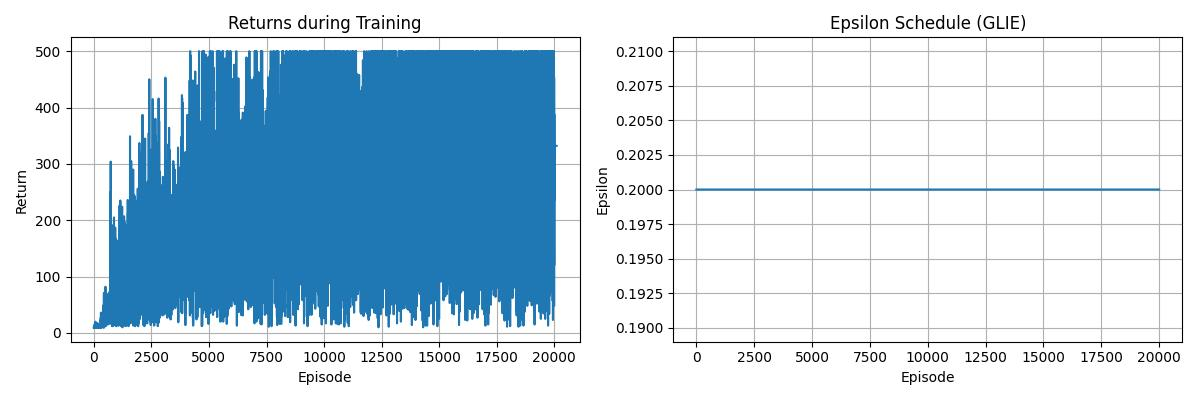
As it is observed as we approximately explore 20% of the random actions and exploit 80% of the greedy actions hence we converge fast towards a maximum reward state without exploring extensively.

GLIE Schedule: Starts with high exploration (ε ≈ 1.0) and gradually reduces to exploitation. Typically performs better as it explores extensively early and exploits knowledge later. The epsilon decays from ~1.0 to ~0.10 over 20000 episodes.
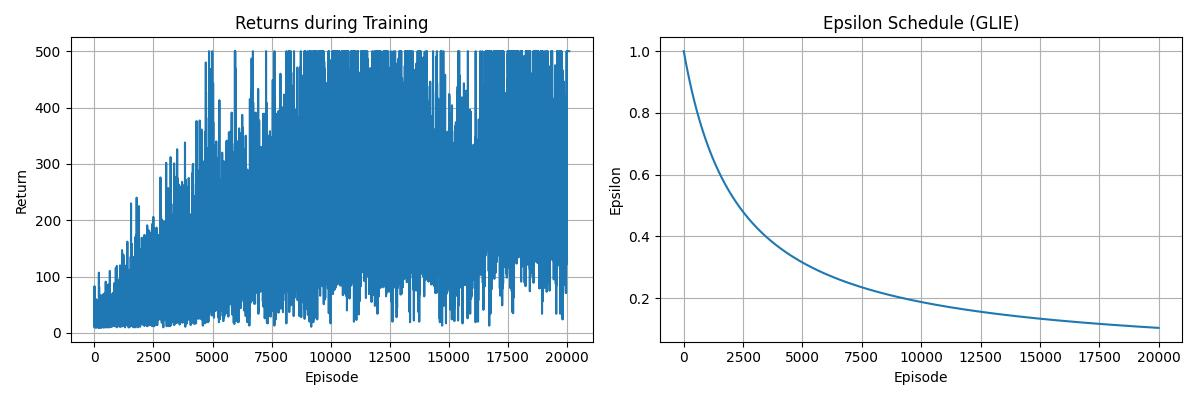
As expected the GLIE method takes longer to explore as we start with maximum exlporation and gradually go to epsilon =0.1 we start have maximum rewards however this model has explored much more than the constant epsilon model even if both have converged  to an optimal solution.

## Task 3.2:
Assuming a greedy policy, use the learned Q-function to compute the associated value function. Plot the heatmap of the computed value function in terms of $\dot{x}$ and $\dot{\theta}$, and therefore average the values over  and  for plotting.

**Hint:** for plotting the heatmap you can use Matplotlib *pyplot.imshow(array)* or Seaborn *seaborn.heatmap(array)* functions.

**Note:** using a greedy policy for the final evaluation is a sensible choice as, if the learned *Q-function* converged to the optimal one, then a greedy policy would effectively be an optimal policy (revise Bellman Optimality Equations in slide 50 of Lecture 5a).

**Guiding questions:**
- What do you think the heatmap would have looked like before the training, after a single episode, and half way through the training?
- Can you intuitively interpret why the heatmap looks the way it does? At least partially.


### Answer 3.2:
I have answered as per the pdf version of the lab hence my plots are wrt position and angle of the cartpole.

The constant episilon greedy policy has been used for this exercise and not GLIE.

As for the Heatmap evolution,intially all states of our cartpole should be equally bad(unrewarded) as they havent been explored yet, after a single episode a random pattern should be observed where the visited states will have a slighly different color as they are the only states that have been visited,Halfway through i expect that the center would be the brightest(aka the most visited) we a pattern starting to settle in where our cartpole bias has started settling due to being epsilon greedy while some areas will be slightly highlighted due exploration however have not be exploited as much and finally after training as observed below  we have a well defined structure at the centre at position 0 and angle 0 and a slightly defined path where the cartpole has determined to be the optimal policy or value function(action value function direction) and still we have slightly less highlighted areas at exploration regions.

Of course there are some gradients to be taken note off such as teh brightness decreases as we approach boundaries where the episode terminates.
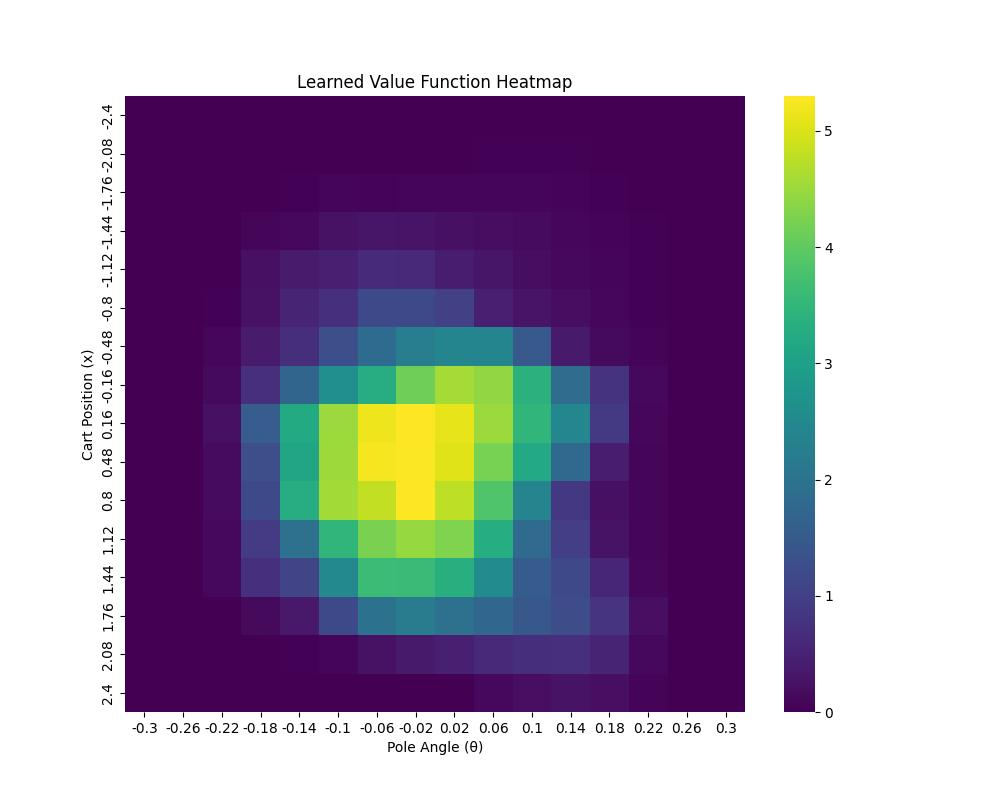

## Task 3.3
Set epsilon to zero, i.e. making the policy greedy w.r.t. the current Q-function estimate. Therefore, run the code again with:
1. keeping the initial Q-function values at zero;
2. setting the initial Q-function values at 50 for all states  and actions;

**Guiding questions:**
- In which case does the model perform better?
- Why is this the case? How does the initialization of Q values affect exploration?

**Hint:** try going through Sec. 2.6 of [1] as a further resource for explaining the behavior in task 3.3.

### Answer 3.3:

Comparing both Q intializations
- Zero intialization:

    Yields very poor results as intially as no states are favoured and has very slow learning as there is a lack of exlporation incentive hence we have a shorter episode length.

- Q=50 Initialization:

    Has much better intial performance and faster learning convergence and the episodes often reach 500.

Reasoning:

This is due to the fact that with Q values intialized somewhat optimistically all actions seem to have some value to them hence there is some incentive to exploration ,however when an action leads to termination its Q value will significally decrease and that state action pair will not be visited again ,hence we have some exploration even if very limited and we have much faster convergence as compared to 0 intialization where we have no convergence observed at all.

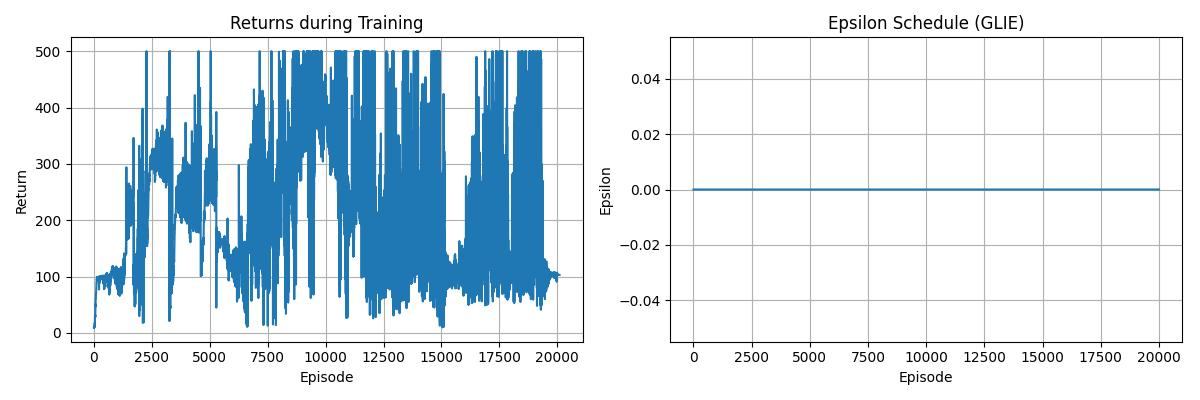
      This is the plot for the Q=50 intialization as Q=0 with 0 epsilon had no convergence at all in 20000 episodes.

## Question 3.4

Can Q-learning be used in environments with continuous state spaces, i.e. with function approximation?

### Answer 3.4:
The answer is Yes it can, Q learning  can be used with continous state spaces using methods such as neural networks,linear function approximaters and other methods, The Q function becomes parameterized and we learn parameters theta that would minzamize the TD error,however we need be aware that generalization and stability of our problem would be fairly difficult.

## Question 3.5
Can Q-learning be used in environments with continuous action spaces? If any, which step of the algorithm would be problematic to compute in the continuous action space case?


### Answer 3.5:

max_action = argmax_{a} Q(s,a)

This line of code becomes untraceable in a continous problem as argmax over infinite actions requires global optimization which is a non convex problem in most cases and is computationally expensive to solve at every timestep.
However it is possible to use other algorithms that we have learned such as actor critic methods that use a seperate policy network and directly outputs the actons.

# 4. Extra: Q-learning with function approximation
Implement Q-learning with function approximation, i.e. without assuming a discrete state space. In the case of continuous state spaces, the learned Q-function must be an approximated, parameterized version of the true Q-function. This way, we interpolate the true Q-function from data and generalize to states that have not been previously explored.

To do this, implement a simple Neural Network in PyTorch, and use gradient descent to update your current estimate of the Q-function.

**Hint:** perform batch updates for better performances, namely update your network with a gradient computed on a batch of recent transitions rather than a single timestep.

**Refer to Chapter 11 of [1] for Off-policy methods with Function Approximation.**

**Note:** this extra step might be considerably time-consuming. In order to implement Q-learning with function approximation, one must consider semi-gradients for the update rule—i.e. the gradients computed by PyTorch backpropagation algorithm should not propagate through the target (bootstrapped) return, despite its value comes from the same network we wish to update. In turn, this is often implemented with target networks, i.e. a copy of the current network that is frozen, used to compute the target values, and then updated with the most recent network after a few iterations.  We suggest the students consider extra time to complete this step, or to even attempt it after the completion of the course.

# References

**[1]** “Reinforcement Learning: An introduction (Second Edition)” by Richard S. Sutton and Andrew G. Barto, [PDF](http://incompleteideas.net/book/RLbook2020.pdf)